In [1]:
# Import libraries for data handling, visualization, preprocessing, and warning control.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings 
warnings.filterwarnings('ignore')


In [2]:
# Load the loan approval dataset from the CSV file into a DataFrame.
df=pd.read_csv("loan_approved.csv")

In [3]:
# Display the first five rows to get a quick look at the dataset.
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
# Count missing values in each column to identify where data cleaning is needed.
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [5]:
# Display the complete DataFrame to inspect the available records and columns.
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


Imputing the null values :

In [6]:
# Count the occurrences of each category in the Gender column.
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [7]:
df.loc[df['Gender'].isnull(),'Gender']="Male" #we have imputed the null value with the Male

In [8]:
df.Gender.isnull().sum()

np.int64(0)

In [11]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0 #we have imputed the null values with CreditHistory

In [12]:
df.Credit_History.isnull().sum()

np.int64(0)

In [14]:
# Replace missing LoanAmount values with the column median.
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()

In [15]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [16]:
df.isnull().sum()

Loan_ID                    0
Gender                     0
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term          14
Credit_History             0
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [17]:
df['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [18]:
# Fill missing Married values with 'yes'.
df.loc[df['Married'].isnull(),'Married']="yes"

In [19]:
df.Married.isnull().sum()

np.int64(0)

In [20]:
df.isnull().sum()

Loan_ID                    0
Gender                     0
Married                    0
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term          14
Credit_History             0
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [21]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [23]:
# Fill missing Dependents values with '0'.
df.loc[df['Dependents'].isnull(),'Dependents']="0"

In [24]:
df.Dependents.isnull().sum()

np.int64(0)

In [25]:
df.isnull().sum()

Loan_ID                    0
Gender                     0
Married                    0
Dependents                 0
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term          14
Credit_History             0
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [26]:
df['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [27]:
# Fill missing Self_Employed values with 'No'.
df.loc[df['Self_Employed'].isnull(),'Self_Employed']="No"

In [28]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [29]:
df.isnull().sum()

Loan_ID                    0
Gender                     0
Married                    0
Dependents                 0
Education                  0
Self_Employed              0
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term          14
Credit_History             0
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [30]:
df['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [33]:
# Replace missing Loan_Amount_Term values with 360 months.
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [34]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

Outliers ::

In [35]:
# Check column names, data types, and non-null counts in the DataFrame.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    str    
 1   Gender                  614 non-null    str    
 2   Married                 614 non-null    str    
 3   Dependents              614 non-null    str    
 4   Education               614 non-null    str    
 5   Self_Employed           614 non-null    str    
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              614 non-null    float64
 9   Loan_Amount_Term        614 non-null    float64
 10  Credit_History          614 non-null    float64
 11  Property_Area           614 non-null    str    
 12  Loan_Status (Approved)  614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.2 KB


Visualizing Outliers :

<Axes: xlabel='LoanAmount'>

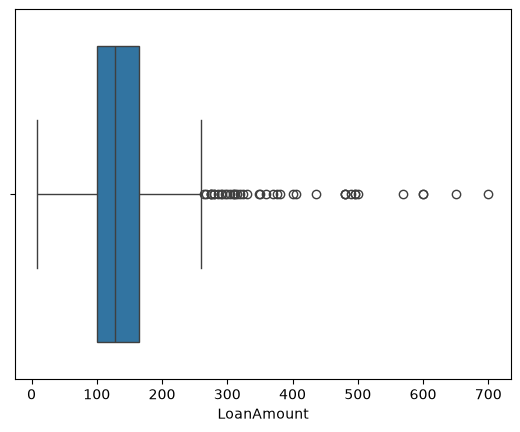

In [37]:
# Draw a box plot to inspect possible outliers in LoanAmount.
sns.boxplot(x=df.LoanAmount ,orient='h')

<Axes: xlabel='ApplicantIncome'>

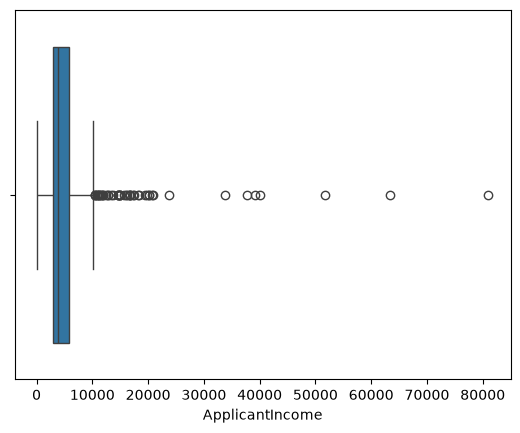

In [38]:
# Draw a box plot to inspect possible outliers in ApplicantIncome.
sns.boxplot(x=df.ApplicantIncome,orient='h')

In [17]:
from scipy.stats.mstats import winsorize

# Specify the percentage of data to be trimmed from both ends

trim_percentage = 0.09

df['ApplicantIncome'] = winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

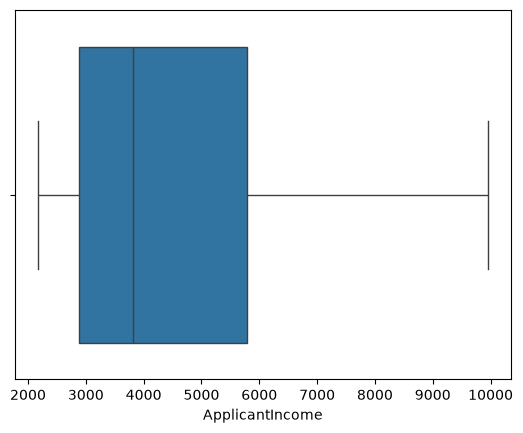

In [18]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

Using IQR method to handle the outliers :

In [46]:
#Calculate quartiles

In [11]:
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)


In [12]:
# Calculate IQR
IQR = Q3-Q1
IQR

np.float64(68.0)

In [18]:
#Define lower and upper bounds
lower_bound = Q1 - 3.5 * IQR
upper_bound = Q3 + 3.5 * IQR


In [19]:
# Display the lower and upper limits calculated using the IQR method.
print(lower_bound)
print(upper_bound)

-138.0
406.0


In [20]:
# Keep only rows whose LoanAmount values fall within the calculated limits.
df = df[(df['LoanAmount'] >=lower_bound) & (df['LoanAmount'] <= upper_bound)]

<Axes: xlabel='LoanAmount'>

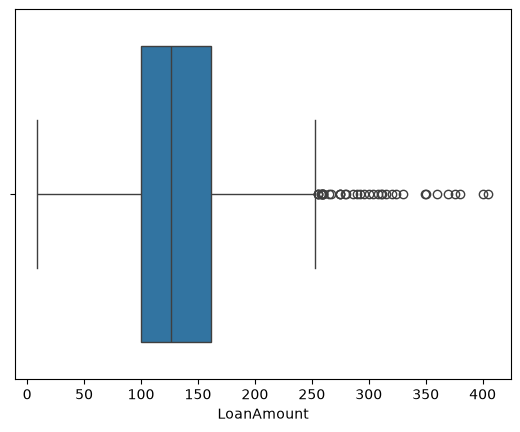

In [21]:
sns.boxplot(x=df.LoanAmount,orient='h')

Using one Hot Encoding :

In [22]:
# Create separate binary columns for the categories in Married (one-hot encoding).
df_encoded = pd.get_dummies(df, columns=['Married'],prefix='Married')

In [23]:
# Display the column names to verify the encoded columns.
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='str')

In [24]:
#from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [25]:
#Fit an transform the 'matchtype' column to obtain label-encoded values
df['Married'] = encoder.fit_transform(df['Married'])

#Display the result

print(df[['Married']])

     Married
1          1
2          1
3          1
4          0
5          1
..       ...
609        0
610        1
611        1
612        1
613        0

[579 rows x 1 columns]


Using Ordinal Encoder

In [26]:
# Count the occurrences of each category in the Education column.
df.Education.value_counts()

Education
Graduate        452
Not Graduate    127
Name: count, dtype: int64

In [30]:
# Create an ordinal encoder with the specified order of Education categories.
Education_enc=OrdinalEncoder(categories=[['Graduate','Not Graduate']])

In [31]:
# Convert Education categories into numeric values using the encoder.
df['Education']= encoder.fit_transform(df[['Education']])

In [32]:
df.Education.value_counts()

Education
0    452
1    127
Name: count, dtype: int64

We can see that we get value for 0 Graduate and 1 for Not Graduate

In [ ]:
#Loan status approved using Label Encoder...

In [33]:
df['Loan_Status (Approved)'] = encoder.fit_transform(df['Loan_Status (Approved)'])

#Display the result

print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
1                         0
2                         1
3                         1
4                         1
5                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[579 rows x 1 columns]


In [4]:
# Display all column names to check the current DataFrame structure.
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

In [29]:
# Apply log(1 + x) transformation to reduce skewness in CoapplicantIncome.
df['CoapplicantIncome'] = np.log1p(df['CoapplicantIncome'])

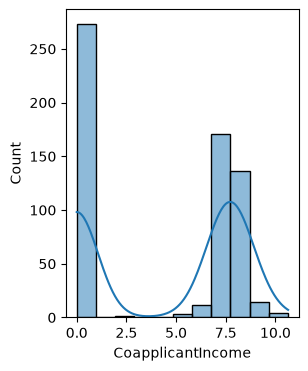

In [30]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde= True) # Target columns
plt.show()

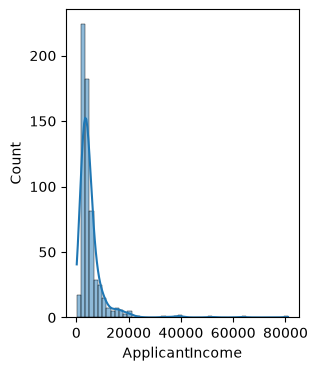

In [6]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde= True) # Target columns
plt.show()

Using Exponential transformers

In [8]:
# Create a new column by applying a power transformation to ApplicantIncome.
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

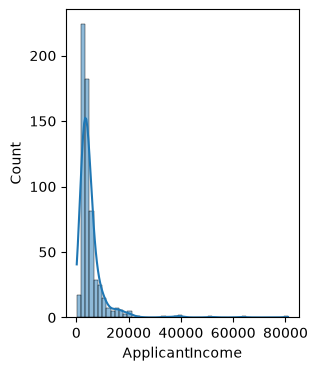

In [9]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde= True) # Target columns
plt.show()

Using square Root Transformation:

In [10]:
# Apply square-root transformation to LoanAmount.
df['LoanAmount']=df.LoanAmount**(1/2)

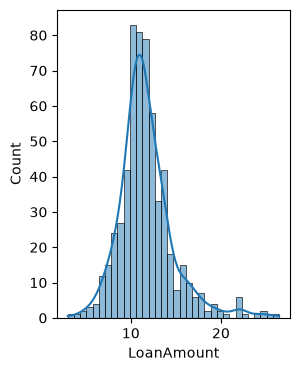

In [11]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde= True) # Target columns
plt.show()

Using Box Cox Transformation:

In [26]:
from scipy.stats import boxcox

transformed_data, lambda_value = boxcox(df['Loan_Amount_Term'])

In [27]:
# Display the values produced by the Box-Cox transformation.
print("Transformed data:",transformed_data)

Transformed data: [1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 6.23871576e+05 1.71794525e+07
 5.05335632e+06 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 2.12092220e+06 1.71794525e+07
 1.717

In [28]:
# Display the lambda parameter selected by the Box-Cox transformation.
print("Lambda value:",lambda_value)

Lambda value: 3.01792025163975


In [22]:
print(df['Loan_Amount_Term'].isnull().sum())

14


In [23]:
# Check the minimum Loan_Amount_Term value before applying Box-Cox.
print(df['Loan_Amount_Term'].min())

12.0


In [24]:
# Replace any remaining missing Loan_Amount_Term values with the median.
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median())

In [25]:
print(df['Loan_Amount_Term'].isnull().sum())

0


Using Standard scalar:

In [8]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='str')

In [6]:
# Standardize ApplicantIncome so it has a mean near 0 and standard deviation near 1.
scaler = StandardScaler()
ApplicantIncome_scaled = scaler.fit_transform(df[['ApplicantIncome']])

In [14]:
# Display the standardized ApplicantIncome values.
print(ApplicantIncome_scaled)

[[ 7.29908229e-02]
 [-1.34411954e-01]
 [-3.93747337e-01]
 [-4.62062470e-01]
 [ 9.77284368e-02]
 [ 2.21831139e-03]
 [-5.03018784e-01]
 [-3.87849628e-01]
 [-2.28939128e-01]
 [ 1.21845703e+00]
 [-3.60982286e-01]
 [-4.75659966e-01]
 [-3.81788093e-01]
 [-5.81654908e-01]
 [-6.72414101e-01]
 [-7.42880841e-02]
 [-2.96107483e-01]
 [-3.10196456e-01]
 [-8.46090753e-02]
 [-4.59277440e-01]
 [ 3.69678365e-01]
 [ 9.03563002e-02]
 [-4.59277440e-01]
 [-3.33951118e-01]
 [-2.76284627e-01]
 [ 6.80946355e-01]
 [-4.26676214e-01]
 [-1.92897571e-01]
 [-6.48987089e-01]
 [-2.70878394e-01]
 [-2.02727086e-01]
 [-3.66388519e-01]
 [-1.16555001e-01]
 [-3.11834708e-01]
 [ 1.16259261e+00]
 [-5.12520649e-01]
 [-5.85750540e-01]
 [-2.84475890e-01]
 [-2.02727086e-01]
 [-2.71206044e-01]
 [-2.95452182e-01]
 [-5.90337647e-01]
 [-4.92042492e-01]
 [-2.39587769e-01]
 [-1.16063525e-01]
 [-3.26578981e-01]
 [ 4.02257712e-02]
 [ 6.84037156e-02]
 [-4.51905304e-01]
 [-2.29922079e-01]
 [-5.69368014e-01]
 [-3.79658365e-01]
 [-1.9224227

In [7]:
#ApplicantIncome_scaled

Using MinMax Scaler:

In [12]:
# Scale ApplicantIncome to a range between 0 and 1 using Min-Max scaling.
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
ApplicantIncome_scaled2 = scaler.fit_transform(df[['ApplicantIncome']])

In [13]:
# Display the Min-Max scaled ApplicantIncome values.
print(ApplicantIncome_scaled2)

[[7.04885591e-02]
 [5.48299320e-02]
 [3.52504638e-02]
 [3.00927644e-02]
 [7.23562152e-02]
 [6.51453309e-02]
 [2.70006184e-02]
 [3.56957328e-02]
 [4.76932591e-02]
 [1.56969697e-01]
 [3.77241806e-02]
 [2.90661719e-02]
 [3.61533704e-02]
 [2.10636982e-02]
 [1.42115028e-02]
 [5.93692022e-02]
 [4.26221398e-02]
 [4.15584416e-02]
 [5.85899814e-02]
 [3.03030303e-02]
 [9.28880643e-02]
 [7.17996289e-02]
 [3.03030303e-02]
 [3.97649969e-02]
 [4.41187384e-02]
 [1.16388374e-01]
 [3.27643785e-02]
 [5.04143476e-02]
 [1.59802103e-02]
 [4.45269017e-02]
 [4.96722325e-02]
 [3.73160173e-02]
 [5.61781076e-02]
 [4.14347557e-02]
 [1.52752010e-01]
 [2.62832406e-02]
 [2.07544836e-02]
 [4.35003092e-02]
 [4.96722325e-02]
 [4.45021645e-02]
 [4.26716141e-02]
 [2.04081633e-02]
 [2.78293135e-02]
 [4.68893012e-02]
 [5.62152134e-02]
 [4.03215832e-02]
 [6.80148423e-02]
 [7.01422387e-02]
 [3.08596166e-02]
 [4.76190476e-02]
 [2.19913420e-02]
 [3.63141620e-02]
 [5.04638219e-02]
 [5.52380952e-02]
 [1.40383426e-01]
 [3.163883

Using Robust Scalar:

In [10]:
# Scale ApplicantIncome using the median and interquartile range.
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
ApplicantIncome_scaled3 = scaler.fit_transform(df[['ApplicantIncome']])

In [11]:
# Display the Robust-scaled ApplicantIncome values.
print(ApplicantIncome_scaled3)

[[ 6.98029135e-01]
 [ 2.64095973e-01]
 [-2.78491859e-01]
 [-4.21422451e-01]
 [ 7.49785775e-01]
 [ 5.49957155e-01]
 [-5.07112254e-01]
 [-2.66152528e-01]
 [ 6.63239075e-02]
 [ 3.09460154e+00]
 [-2.09940017e-01]
 [-4.49871465e-01]
 [-2.53470437e-01]
 [-6.71636675e-01]
 [-8.61525278e-01]
 [ 3.89888603e-01]
 [-7.42073693e-02]
 [-1.03684662e-01]
 [ 3.68294773e-01]
 [-4.15595544e-01]
 [ 1.31876607e+00]
 [ 7.34361611e-01]
 [-4.15595544e-01]
 [-1.53384747e-01]
 [-3.27335047e-02]
 [ 1.97000857e+00]
 [-3.47386461e-01]
 [ 1.41730934e-01]
 [-8.12510711e-01]
 [-2.14224507e-02]
 [ 1.21165381e-01]
 [-2.21251071e-01]
 [ 3.01456727e-01]
 [-1.07112254e-01]
 [ 2.97772065e+00]
 [-5.26992288e-01]
 [-6.80205656e-01]
 [-4.98714653e-02]
 [ 1.21165381e-01]
 [-2.21079692e-02]
 [-7.28363325e-02]
 [-6.89802913e-01]
 [-4.84147386e-01]
 [ 4.40445587e-02]
 [ 3.02485004e-01]
 [-1.37960583e-01]
 [ 6.29477292e-01]
 [ 6.88431877e-01]
 [-4.00171380e-01]
 [ 6.42673522e-02]
 [-6.45929734e-01]
 [-2.49014567e-01]
 [ 1.4310197